# Phase 11 — Finalisation

**Objectifs:**
- [x] Dashboard
- [x] Documentation
- [x] Architecture Diagram
- [x] Screenshots
- [x] Démonstration complète
- [x] Publication GitHub

**Livrable:** Portfolio Ready

Dernière étape: rendre le projet **présentable** (dashboard, documentation, diagramme, captures) et **vérifier de bout en bout** que tout fonctionne.

## 0. Setup

In [1]:
from lakehouse_config import *
spark = get_spark()

from pyspark.sql import functions as F
import pandas as pd
import os
import matplotlib.pyplot as plt
os.makedirs('docs/screenshots', exist_ok=True)

## 1. Dashboard
### 1.1 Aperçu du dashboard (généré depuis les tables Gold)

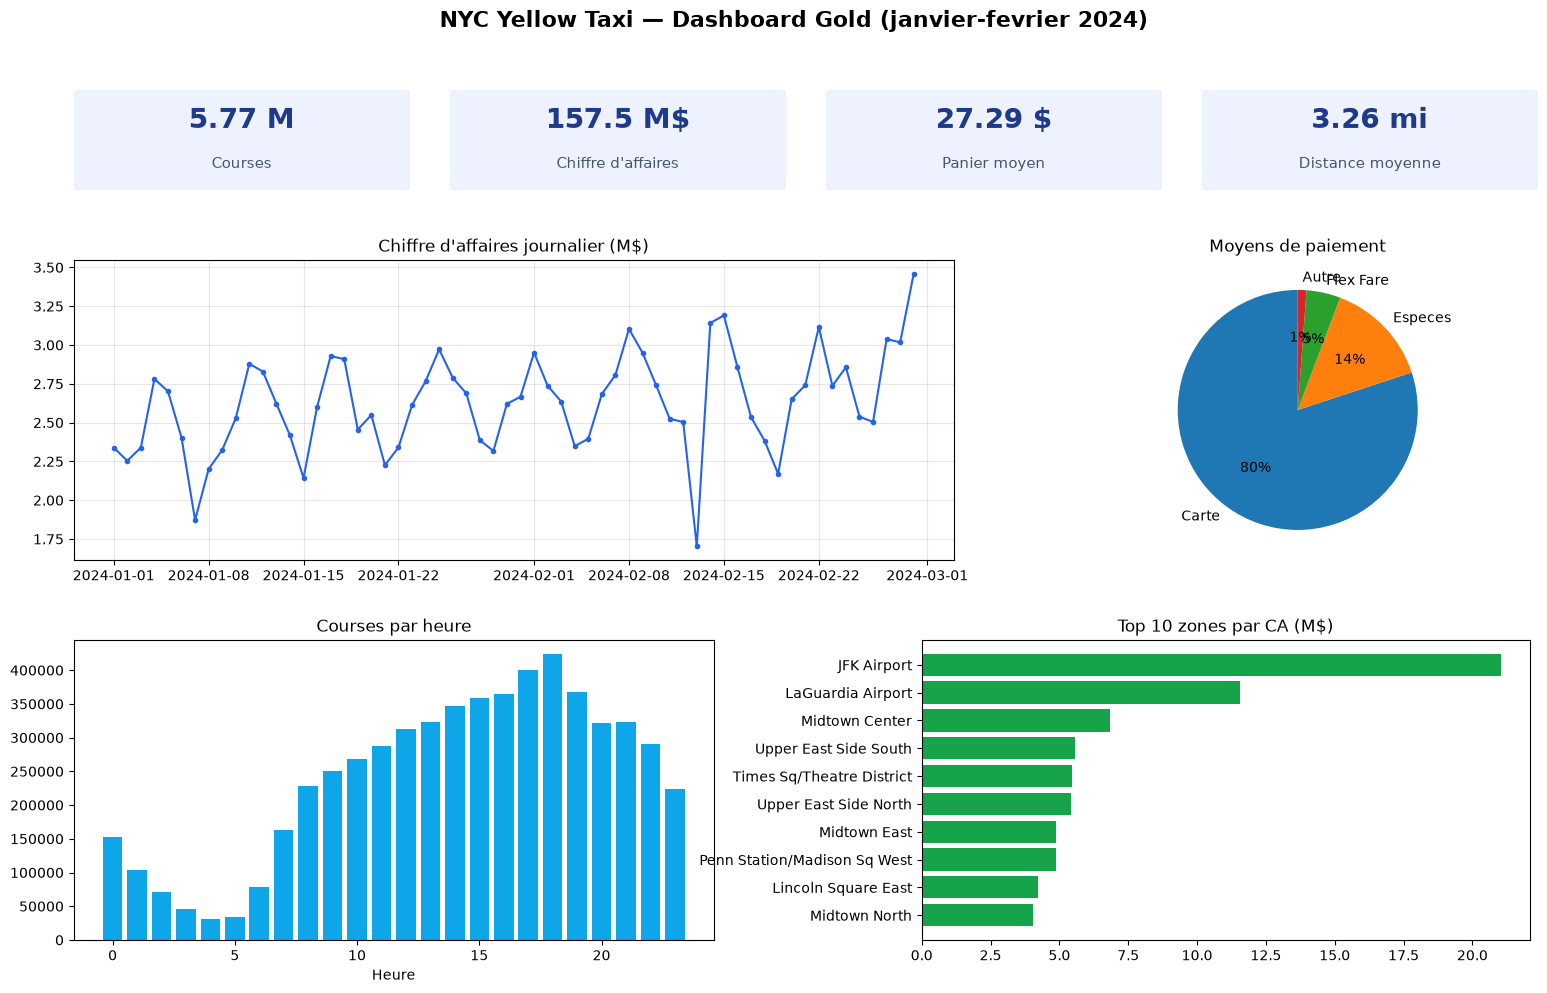

In [2]:
kpi = spark.sql(f"""
    SELECT COUNT(*) AS courses, SUM(total_amount) AS ca, AVG(total_amount) AS panier, AVG(trip_distance) AS distance
    FROM {T_GOLD_FACT_TRIPS}""").collect()[0]
daily = spark.table(T_GOLD_DAILY_KPIS).orderBy("date").toPandas()
daily["total_revenue"] = daily["total_revenue"].astype(float)   # decimal -> float pour matplotlib
hours = spark.sql(f"SELECT pickup_hour, COUNT(*) AS courses FROM {T_GOLD_FACT_TRIPS} GROUP BY 1 ORDER BY 1").toPandas()
pay = spark.sql(f"""SELECT CASE payment_type WHEN 1 THEN 'Carte' WHEN 2 THEN 'Especes' WHEN 0 THEN 'Flex Fare' ELSE 'Autre' END AS p,
                    COUNT(*) AS n FROM {T_GOLD_FACT_TRIPS} GROUP BY 1 ORDER BY n DESC""").toPandas()
zones_top = spark.sql(f"SELECT zone, CAST(total_revenue AS DOUBLE) AS total_revenue FROM {T_GOLD_ZONE_KPIS} ORDER BY 2 DESC LIMIT 10").toPandas()

fig = plt.figure(figsize=(16, 10))
fig.suptitle("NYC Yellow Taxi — Dashboard Gold (janvier-fevrier 2024)", fontsize=16, fontweight="bold")
tiles = [("Courses", f"{kpi.courses / 1e6:.2f} M"), ("Chiffre d'affaires", f"{float(kpi.ca) / 1e6:.1f} M$"),
         ("Panier moyen", f"{float(kpi.panier):.2f} $"), ("Distance moyenne", f"{kpi.distance:.2f} mi")]
for i, (label, value) in enumerate(tiles):
    ax = fig.add_axes([0.05 + i * 0.235, 0.80, 0.21, 0.10]); ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, color="#eef2ff", transform=ax.transAxes))
    ax.text(0.5, 0.62, value, ha="center", fontsize=20, fontweight="bold", color="#1e3a8a")
    ax.text(0.5, 0.22, label, ha="center", fontsize=11, color="#475569")

ax1 = fig.add_axes([0.05, 0.43, 0.55, 0.30])
ax1.plot(daily["date"], daily["total_revenue"] / 1e6, marker="o", ms=3, color="#2563eb")
ax1.set_title("Chiffre d'affaires journalier (M$)"); ax1.grid(alpha=0.3)
ax2 = fig.add_axes([0.67, 0.43, 0.29, 0.30])
ax2.pie(pay["n"], labels=pay["p"], autopct="%1.0f%%", startangle=90); ax2.set_title("Moyens de paiement")
ax3 = fig.add_axes([0.05, 0.05, 0.40, 0.30])
ax3.bar(hours["pickup_hour"], hours["courses"], color="#0ea5e9"); ax3.set_title("Courses par heure"); ax3.set_xlabel("Heure")
ax4 = fig.add_axes([0.58, 0.05, 0.38, 0.30])
ax4.barh(zones_top["zone"][::-1], zones_top["total_revenue"][::-1] / 1e6, color="#16a34a"); ax4.set_title("Top 10 zones par CA (M$)")

fig.savefig("docs/screenshots/dashboard.png", dpi=110, bbox_inches="tight")
plt.show()

### 1.2 Dashboard Databricks (AI/BI)
Dans Databricks: **Dashboards → Create dashboard** → onglet **Data** → ajouter les requêtes ci-dessous → onglet **Canvas** → ajouter les visualisations → **Publish**.

| Visualisation | Requête |
|---|---|
| Compteurs KPI | `SELECT COUNT(*) courses, SUM(total_amount) ca, AVG(total_amount) panier FROM workspace.gold.fact_trips` |
| Ligne: CA par jour | `SELECT date, total_revenue, total_trips FROM workspace.gold.kpi_daily ORDER BY date` |
| Barres: courses par heure | `SELECT pickup_hour, COUNT(*) courses FROM workspace.gold.fact_trips GROUP BY 1` |
| Camembert: paiements | `SELECT payment_type, COUNT(*) n FROM workspace.gold.fact_trips GROUP BY 1` |
| Barres: top zones | `SELECT zone, total_revenue FROM workspace.gold.kpi_pickup_zone ORDER BY 2 DESC LIMIT 10` |
| Carte de qualité | `SELECT rule_name, status, pass_rate FROM workspace.ops.dq_results WHERE run_ts = (SELECT MAX(run_ts) FROM workspace.ops.dq_results WHERE run_id <> 'demo')` |

## 2. Documentation
Le `README.md` présente le projet (objectif, architecture, stack, résultats, exécution).

In [3]:
print(open("README.md", encoding="utf-8").read()[:3000])

# 🚕 Lakehouse Databricks — NYC Yellow Taxi

Pipeline de données **end-to-end** sur **Databricks** avec une architecture **Medallion (Bronze / Silver / Gold)**, **Delta Lake**, **Unity Catalog**, un framework de **Data Quality**, un traitement **incrémental (MERGE)**, une **orchestration** par Databricks Workflows et une chaîne **CI/CD** GitHub Actions.

**Données:** [NYC TLC Yellow Taxi Trip Records](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) — janvier et février 2024 (**~6 millions de courses**) + référentiel des 265 zones.

![Dashboard](docs/screenshots/dashboard.png)

---

## 🏗️ Architecture

```mermaid
flowchart LR
    TLC["NYC TLC<br/>Parquet mensuels"] --> RAW["raw.landing<br/>(Volume UC)"]
    CSV["taxi_zone_lookup.csv"] --> RAW
    RAW -->|ingestion + metadata| BRZ["🥉 Bronze<br/>yellow_trips · taxi_zones"]
    BRZ -->|cast · nulls · règles · dédup · MERGE| SLV["🥈 Silver<br/>yellow_trips · taxi_zones"]
    BRZ -->|lignes invalides + motif| REJ["Silver<br/>yell

## 3. Architecture Diagram

```mermaid
flowchart LR
    TLC["NYC TLC<br/>Parquet mensuels"] -->|upload_to_volume| RAW["raw.landing<br/>(Volume UC)"]
    CSV["taxi_zone_lookup.csv"] --> RAW
    RAW -->|Phase 3: ingestion + metadata| BRZ["Bronze<br/>yellow_trips, taxi_zones"]
    BRZ -->|Phase 4/7: cast, nulls, regles, dedup, MERGE| SLV["Silver<br/>yellow_trips, taxi_zones"]
    BRZ -->|lignes invalides| REJ["Silver<br/>yellow_trips_rejected"]
    SLV -->|Phase 5: etoile + KPIs| GLD["Gold<br/>fact_trips, dim_*, kpi_*"]
    GLD --> DASH["Dashboard AI/BI"]
    SLV -.->|Phase 6| DQ["ops.dq_results"]
    GLD -.->|Phase 6| DQ
    BRZ -.-> LOG["ops.ingestion_log"]
    JOB["Databricks Workflow<br/>(Phase 9)"] -.orchestrate.-> BRZ & SLV & GLD & DQ
    GH["GitHub Actions<br/>(Phase 10)"] -.deploy.-> JOB
```
*(Le diagramme Mermaid est rendu automatiquement sur GitHub dans le README.)*

## 4. Screenshots

| Capture | Où la prendre | Fichier |
|---|---|---|
| Dashboard | Généré ci-dessus / Dashboard AI/BI publié | `docs/screenshots/dashboard.png` ✅ |
| Catalog Explorer (schémas bronze/silver/gold/ops) | Catalog → workspace | `docs/screenshots/catalog.png` |
| Lineage graph de `gold.fact_trips` | Catalog → table → Lineage → graph | `docs/screenshots/lineage.png` |
| Job et ses 3 tâches | Jobs & Pipelines → job → Tasks | `docs/screenshots/workflow.png` |
| Run réussi du Job | Jobs & Pipelines → Runs | `docs/screenshots/job_run.png` |
| GitHub Actions vert | Dépôt GitHub → Actions | `docs/screenshots/ci.png` |

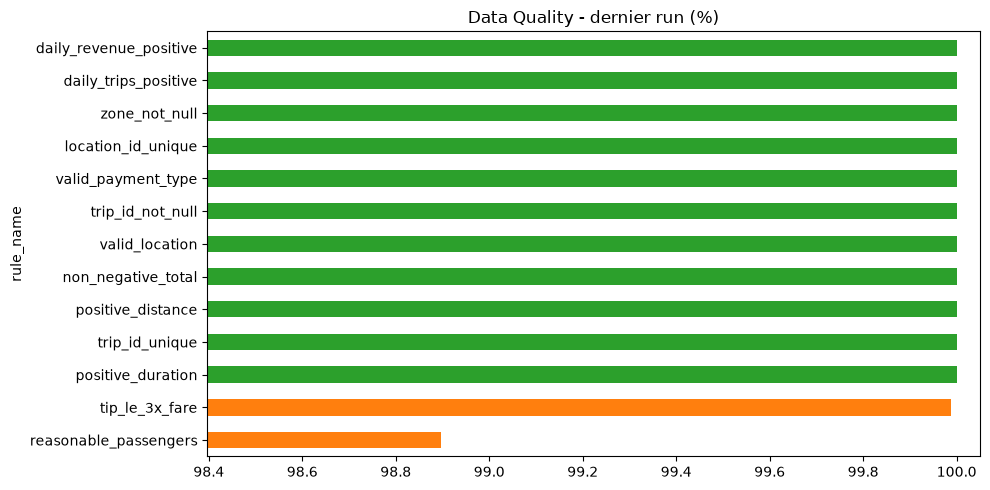

['dashboard.png', 'data_quality.png']


In [4]:
# Capture automatique du rapport Data Quality
dq = spark.sql(f"""SELECT rule_name, severity, status, pass_rate FROM {T_DQ_RESULTS}
                  WHERE run_ts = (SELECT MAX(run_ts) FROM {T_DQ_RESULTS} WHERE run_id <> 'demo')""").toPandas().sort_values("pass_rate")
colors = ["tab:red" if s != "PASS" and v == "critical" else "tab:orange" if s != "PASS" else "tab:green" for s, v in zip(dq.status, dq.severity)]
ax = dq.plot.barh(x="rule_name", y="pass_rate", color=colors, legend=False, figsize=(10, 5), title="Data Quality - dernier run (%)")
ax.set_xlim(max(dq.pass_rate.min() - 0.5, 0), 100.05); plt.tight_layout()
plt.savefig("docs/screenshots/data_quality.png", dpi=110); plt.show()
print(sorted(os.listdir("docs/screenshots")))

## 5. Démonstration complète — vérification de bout en bout
Ordre d'exécution du projet: **Phase 1 → 2 → 3 → 4 → 5 → 6 → 7** (puis le Job de la Phase 9 rejoue 7 → 5 → 6 automatiquement).

In [5]:
checks = []
def check(name, ok, detail=""):
    checks.append((name, "OK" if ok else "KO", detail))

counts = {t: spark.table(t).count() for t in [T_BRONZE_TRIPS, T_SILVER_TRIPS, T_SILVER_REJECTED, T_GOLD_FACT_TRIPS,
                                             T_GOLD_DIM_ZONE, T_GOLD_DIM_DATE, T_GOLD_DAILY_KPIS, T_GOLD_ZONE_KPIS,
                                             T_DATA_DICTIONARY, T_INGESTION_LOG, T_DQ_RESULTS]}
for t, n in counts.items():
    check(f"table {t} non vide", n > 0, f"{n:,} lignes")

dups = spark.table(T_SILVER_TRIPS).groupBy("trip_id").count().filter("count > 1").count()
check("Silver sans doublon (trip_id)", dups == 0, f"{dups} doublons")

b, s, r = counts[T_BRONZE_TRIPS], counts[T_SILVER_TRIPS], counts[T_SILVER_REJECTED]
check("Reconciliation Bronze >= Silver + Rejected", b >= s + r, f"{b:,} >= {s + r:,} (ecart = doublons)")
check("Gold fact = Silver", counts[T_GOLD_FACT_TRIPS] == s, f"{counts[T_GOLD_FACT_TRIPS]:,} vs {s:,}")

last_dq = spark.sql(f"""SELECT SUM(CASE WHEN severity='critical' AND status<>'PASS' THEN 1 ELSE 0 END) AS crit
                        FROM {T_DQ_RESULTS} WHERE run_ts = (SELECT MAX(run_ts) FROM {T_DQ_RESULTS} WHERE run_id <> 'demo')""").collect()[0].crit
check("Dernier run DQ sans echec critique", last_dq == 0, f"{last_dq} echec(s) critique(s)")

files = spark.table(T_INGESTION_LOG).filter("status = 'SUCCESS'").select("file_name").distinct().count()
check("Fichiers ingeres (log)", files >= 2, f"{files} fichiers")

result = pd.DataFrame(checks, columns=["controle", "statut", "detail"])
print(f"{(result.statut == 'OK').sum()} / {len(result)} controles OK")
result

16 / 16 controles OK


,controle,statut,detail
0,table workspace.bronze.yellow_trips non vide,OK,"5,972,150 lignes"
1,table workspace.silver.yellow_trips non vide,OK,"5,771,620 lignes"
2,table workspace.silver.yellow_trips_rejected n...,OK,"200,529 lignes"
3,table workspace.gold.fact_trips non vide,OK,"5,771,620 lignes"
4,table workspace.gold.dim_zone non vide,OK,265 lignes
5,table workspace.gold.dim_date non vide,OK,60 lignes
6,table workspace.gold.kpi_daily non vide,OK,60 lignes
7,table workspace.gold.kpi_pickup_zone non vide,OK,260 lignes
8,table workspace.ops.data_dictionary non vide,OK,23 lignes
9,table workspace.ops.ingestion_log non vide,OK,2 lignes


## 6. Publication GitHub

```bash
# 1. Verifier ce qui sera publie (pas de .venv, data/, secrets)
git status

# 2. Commit
git add .
git commit -m "Lakehouse NYC Taxi: phases 1 a 11 (Bronze/Silver/Gold, DQ, incremental, UC, workflow, CI/CD)"

# 3. Creer le depot GitHub et pousser (GitHub CLI)
gh repo create Lakehouse-Databricks --public --source . --push

# 4. Ajouter les secrets pour la CI/CD
gh secret set DATABRICKS_HOST  --body "https://dbc-8e6d5a22-8ef2.cloud.databricks.com"
gh secret set DATABRICKS_TOKEN --body "<votre token>"
```

**Checklist portfolio:**
- [ ] README avec diagramme d'architecture et captures
- [ ] Notebooks exécutés (avec résultats visibles)
- [ ] Badge CI vert sur le dépôt
- [ ] Description et *topics* du dépôt GitHub: `databricks`, `pyspark`, `delta-lake`, `data-engineering`, `lakehouse`
- [ ] Post LinkedIn avec la capture du dashboard

## 🎯 Projet terminé — Portfolio Ready